## SoCG examples

In [4]:
import gudhi
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import matplotlib
import matplotlib.patches as mpatches

from matplotlib import rc

# rc('font',**{'family':'sans-serif','sans-serif':['Helvetica']})
rc("font", **{"family": "serif", "serif": ["Times"]})
rc("text", usetex=True)


from math import cos, sin, pi, atan     
import itertools
from scipy.stats import qmc
import math

import numpy.linalg
import random as rnd

## for checking if in convex hull
import scipy.spatial
from scipy.optimize import linprog

import sys 
sys.path.append('../Code/')
import modules as mod
import examples as ex
import plot as ourplot
import csv
import bunny_smaller
import omega_pts as omega
# This reloads external modules every time a cell is run
# so we don't have to reboot kernel every time we modify classes.py
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload




## notes
- output a table: num pts in M and num in N, num omega (unpruned), num omega (pruned) (for each of the three algs)
- pictures of input points (and/or with switch points)


## experiments to comment on: 
- increasing num of rect mods, and seeing how num of omega pts increase
- seeing how unbalanced M vs N changes omega pts
- what is the dependence of num of switch points on num of pts in M and N? 
- unbalanced modules: M has more points than N
- How many duplcate omega points do we get in different cases? 

- multiple instances of 1 rect vs 1 rect
- experiments where num rects increases

## Poisson points with blue noise

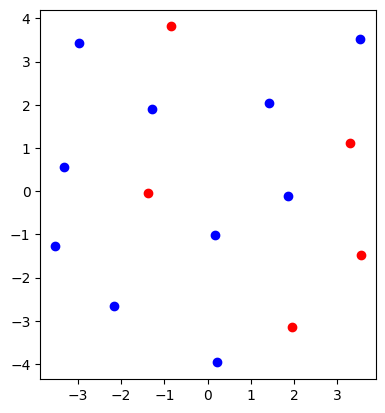

In [6]:

poisson_intensity = 5
seed = 0

critvals = ex.critvals_poisson(poisson_intensity, seed)


## Flattened bunny

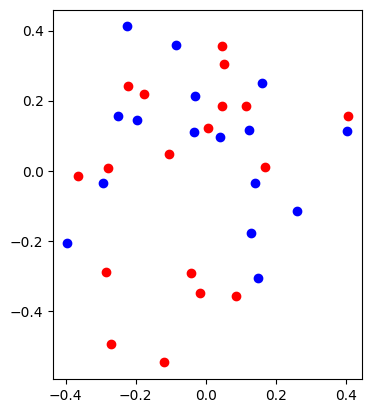

In [8]:
bunnypoints = bunny_smaller.bunnysmaller()
seed = 4
critvals = ex.bunny_into_critvals(bunnypoints, seed)


## Random rect mods

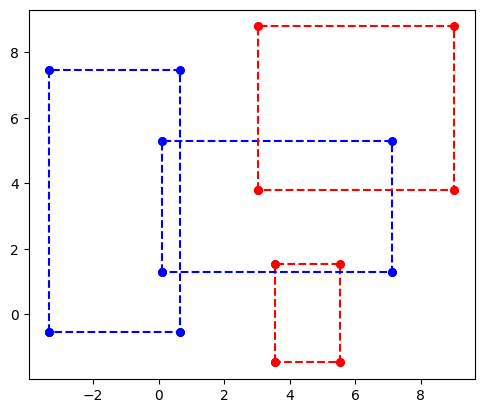

In [4]:
poisson_intensity = 1.2
seed = 2

critpts = ex.make_rects(poisson_intensity, seed = seed)


## sanity check example

NOTE!!! These figures include infinite omega points. 
\e can discard them, but we have to do that in the omega points file, where we still have the info that they have an omega slope. 

- color the pts differently if from two modules
- draw quarter circle, line with slope m intersects circle at a point, draw that point to repr slope

- is 3v1 never infinite? 

- order is different between csv and output

**********
Computed 83 points (with duplicates)
Without duplicates 24


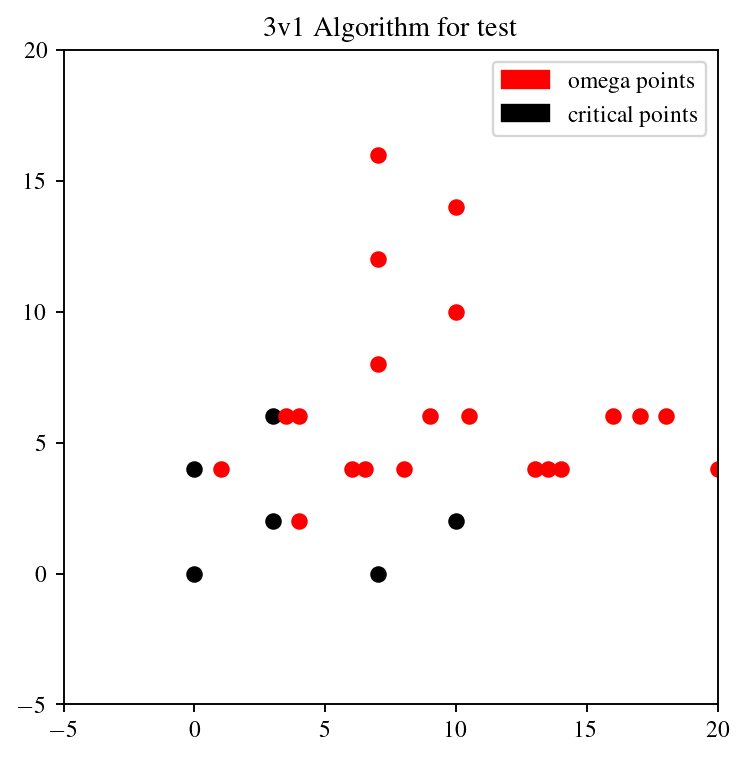

**********
Computed 17 points (with duplicates)
Without duplicates 10
['m', 0.5714285714285714, 0.6666666666666666, 0.5714285714285714, 1.5, 0.6666666666666666, 2.0, 0.2, 0.2, 1.7142857142857142, 0.5]
['omega_pts', (0, 7.0, 4.0), (0, 6.0, 4.0), (0, 14.0, 8.0), (0, 4.0, 6.0), (0, 3.0, 2.0), (0, 3.0, 6.0), (0, 10.0, 2.0), (0, 20.0, 4.0), (0, 7.0, 12.0), (0, 4.0, 2.0)]


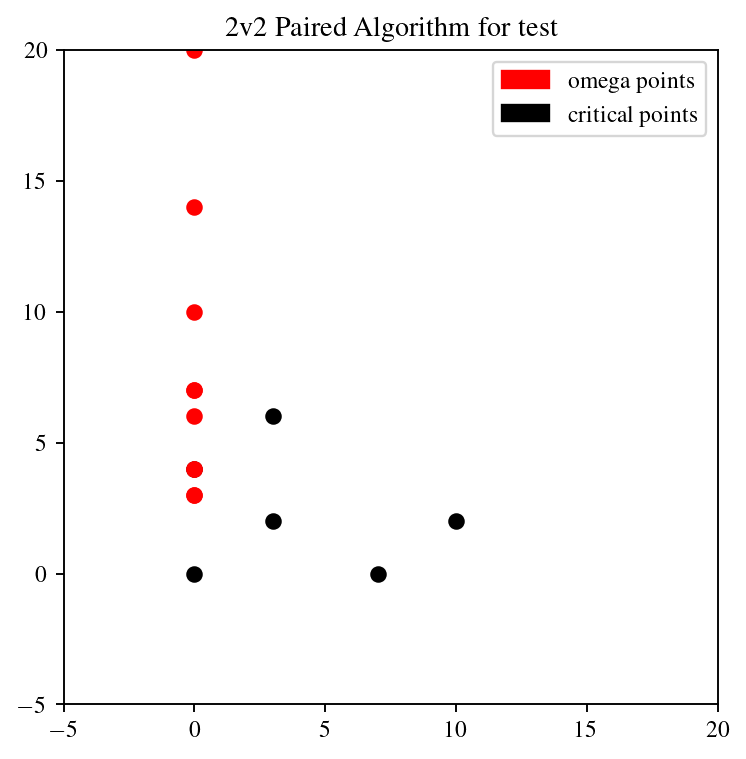

**********
Computed 20 points (with duplicates)
Without duplicates 16
['m', None, None, None, 1.5, None, None, 0.2, None, None, 0.5, 0.6666666666666666, None, None, None, None, None]
['omega_pts', (3.5, 4.0), (-1.0, -4.0), (3.5, 2.0), (-4.0, -6.0), (3.5, 6.0), (8.5, 3.0), (10.0, 2.0), (5.0, 3.0), (5.0, 5.0), (-4.0, -2.0), (3.0, 2.0), (8.5, 5.0), (11.0, 6.0), (5.666666666666667, 6.0), (8.0, 4.666666666666667), (7.666666666666667, 4.666666666666667)]


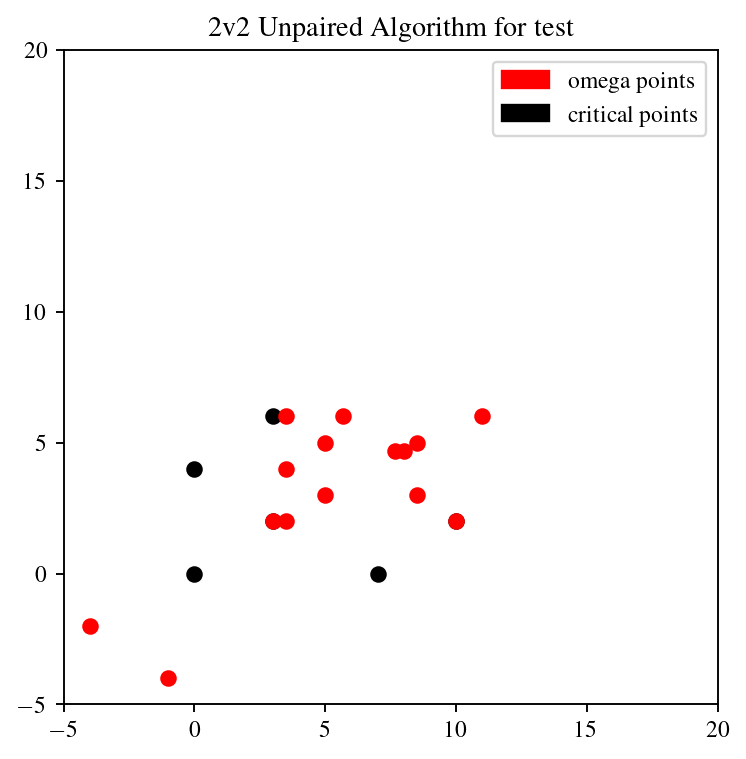

In [33]:
critpts = ex.test_example()
title = "test"
dpi = 170

# algo 3v1 = Algorithm 3 in SoCG overleaf
# never has points at infinity
omegapts_3v1, _, _ = omega.output_alg_3_1(critpts, "socg/" + title)
ourplot.plot_both_c_o(critpts, omegapts_3v1, title, dpi, "3v1")


# NOte: for sanity example, these are all slopes, 
# #and one is on top of a black point, that is why it looks weird.
# algo 2v2 paired = Algorithm 5 in SoCG overleaf
omegapts_2v2_p, _, _ , is_inf, orderedomegas = omega.output_alg_2_2_paired(critpts, "socg/" + title)
ourplot.plot_both_c_o(critpts, omegapts_2v2_p, title, dpi, "2v2 Paired")

# algo 2v2 unpaired = Algorithm 7 in SoCG overleaf
omegapts_2v2_unp, _, _ , is_inf, orderedomegas = omega.output_alg_2_2_unpaired(critpts, "socg/" + title)
ourplot.plot_both_c_o(critpts, omegapts_2v2_unp, title, dpi, "2v2 Unpaired")

In [18]:
for line in omegapts_3v1:
    print(line)

(14.0, 4.0)
(3.5, 6.0)
(27.0, 4.0)
(13.5, 4.0)
(4.0, 6.0)
(30.0, 6.0)
(17.0, 6.0)
(6.5, 4.0)
(20.0, 4.0)
(7.0, 16.0)
(4.0, 2.0)
(23.0, 6.0)
(13.0, 4.0)
(10.0, 14.0)
(6.0, 4.0)
(16.0, 6.0)
(18.0, 6.0)
(7.0, 12.0)
(8.0, 4.0)
(9.0, 6.0)
(1.0, 4.0)
(10.5, 6.0)
(10.0, 10.0)
(7.0, 8.0)
